In [3]:
import os
import numpy as np
import tensorflow as tf
import cv2
import pandas as pd
import seaborn as sns
import joblib
import matplotlib.pyplot as plt


from tqdm import tqdm
from scipy.stats import skew, kurtosis
from skimage.feature import graycomatrix, graycoprops, hog, local_binary_pattern
from sklearn.model_selection import train_test_split, cross_val_score, learning_curve
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from skimage.feature import hog
import math
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


In [4]:
# 参数定义
IMG_SIZE = 512
WIDTH, LENGTH = 4, 4
TRAIN_INPUT_DIR = 'F:/B208/High_density/ML_generation/image_train/'
TRAIN_LABEL_DIR = 'F:/B208/High_density/ML_generation/txt_train/'
MODEL_SAVE_PATH = 'F:/B208/High_density/1ML_generation/Model/RandomForestRegressor.pkl'


In [5]:
# 读取灰度图像
def load_image(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    return img.astype(np.float32) / 255.0 if img is not None else None

# 计算统计特征，仅保留 Mean
def compute_mean(img):
    return {"Mean": np.mean(img)}

# 处理所有训练数据
features_list = []
image_files = sorted(os.listdir(TRAIN_INPUT_DIR))
label_files = sorted(os.listdir(TRAIN_LABEL_DIR))

for image_name, label_name in tqdm(zip(image_files, label_files), total=len(image_files), desc="Processing Data"):
    image_path = os.path.join(TRAIN_INPUT_DIR, image_name)
    label_path = os.path.join(TRAIN_LABEL_DIR, label_name)

    image = load_image(image_path)
    if image is None:
        print(f"Warning: Unable to load {image_path}")
        continue

    with open(label_path, 'r') as f:
        lines = f.readlines()

    for line in lines:
        x_start, x_end, y_start, y_end, density = map(float, line.strip().split())
        x_start, x_end, y_start, y_end = int(x_start), int(x_end), int(y_start), int(y_end)

        block_image = cv2.resize(image[y_start:y_end, x_start:x_end], (WIDTH, LENGTH))
        block_features = compute_mean(block_image)
        block_features["Density"] = density  # 仅保留 Mean 和 Density

        features_list.append(block_features)

# 创建 DataFrame 并保存
df = pd.DataFrame(features_list)


Processing Data: 100%|██████████| 1/1 [00:00<00:00,  9.06it/s]


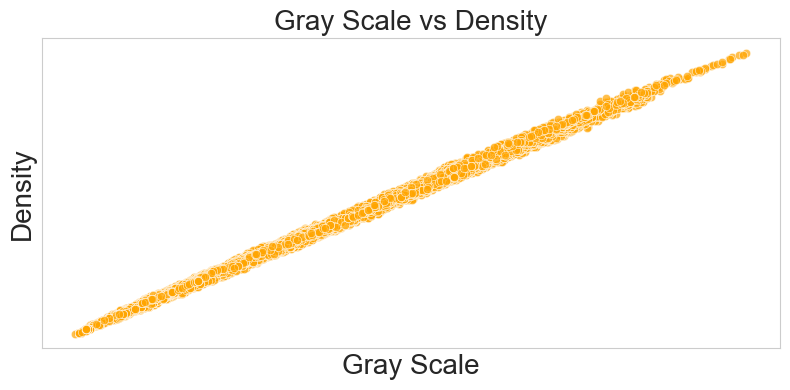

In [23]:
# 数据可视化
sns.set_style("whitegrid")
plt.figure(figsize=(8, 4))

feature_columns = ["Mean"]

# Calculate number of rows and columns for the subplot grid
num_features = len(feature_columns)
num_cols = 1  # You can set the number of columns to 3 (or another number)
num_rows = math.ceil(num_features / num_cols)  # Number of rows based on the number of features

# Create subplots
for i, feature in enumerate(feature_columns, 1):
    plt.subplot(num_rows, num_cols, i)  # Use dynamic rows and columns
    sns.scatterplot(x=df[feature], y=df['Density'], color='orange', alpha=0.7)
    plt.title('Gray Scale vs Density', fontsize=20)
    plt.xlabel('Gray Scale', fontsize=20)
    plt.ylabel('Density',fontsize=20)

plt.gca().yaxis.set_ticks([])
plt.gca().xaxis.set_ticks([])
plt.tight_layout()
plt.show()
                                    
# 特征和标签分离
X = df.drop('Density', axis=1)
y = df['Density']


# 数据集划分（80%训练，20%测试）
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [7]:

# 集成学习模型（这里使用 XGBoost 作为例子）
model = RandomForestRegressor(n_estimators=200, random_state=42)  # 使用GPU加速
model.fit(X_train, y_train)


RandomForestRegressor(n_estimators=200, random_state=42)

RMSE: 0.7953352616023698, R²: 0.9976979415956899
Cross-validation RMSE: 0.8360436371562994, R²: 0.9972476930492741


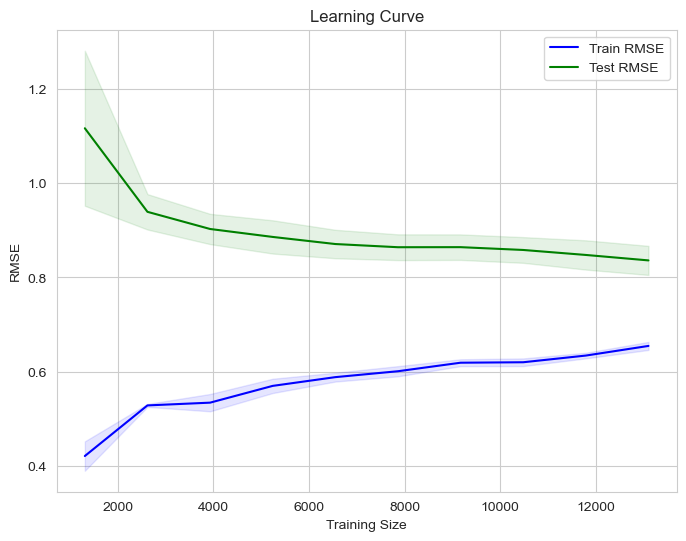

In [8]:

# 预测与评估
y_pred = model.predict(X_test)
rmse, r2 = np.sqrt(mean_squared_error(y_test, y_pred)), r2_score(y_test, y_pred)
print(f"RMSE: {rmse}, R²: {r2}")

# 交叉验证
cv_r2 = cross_val_score(model, X, y, cv=5, scoring='r2').mean()
cv_rmse = -cross_val_score(model, X, y, cv=5, scoring='neg_root_mean_squared_error').mean()
print(f"Cross-validation RMSE: {cv_rmse}, R²: {cv_r2}")

# 学习曲线
train_sizes, train_scores, test_scores = learning_curve(
    model, X, y, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1, train_sizes=np.linspace(0.1, 1.0, 10)
)

plt.figure(figsize=(8, 6))
plt.plot(train_sizes, -train_scores.mean(axis=1), label='Train RMSE', color='blue')
plt.plot(train_sizes, -test_scores.mean(axis=1), label='Test RMSE', color='green')
plt.fill_between(train_sizes, -train_scores.mean(axis=1) - train_scores.std(axis=1), 
                 -train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.1, color='blue')
plt.fill_between(train_sizes, -test_scores.mean(axis=1) - test_scores.std(axis=1), 
                 -test_scores.mean(axis=1) + test_scores.std(axis=1), alpha=0.1, color='green')
plt.xlabel('Training Size')
plt.ylabel('RMSE')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)
plt.show()


In [9]:

# 保存模型
joblib.dump(model, MODEL_SAVE_PATH)
print(f"Model saved to {MODEL_SAVE_PATH}")

FileNotFoundError: [Errno 2] No such file or directory: 'F:/B208/High_density/1ML_generation/Model/RandomForestRegressor.pkl'